<a href="https://colab.research.google.com/github/MBR4V0/Python/blob/main/gerador_arte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎨 Gerador de Arte — aprende com obras e cria a partir de diretrizes

**Fluxo:**
1. **Ler** — você envia as imagens das obras.
2. **Analisar** — o programa extrai paleta, brilho, contraste, traço, composição, legenda e estilo (via CLIP + BLIP).
3. **Sintetizar** — tudo vai para um banco de dados (SQLite + embeddings) e vira um *perfil de estilo*.
4. **Criar** — você pede um quadro/design + diretrizes; ele busca as obras mais parecidas no banco e gera a imagem (Stable Diffusion + IP-Adapter usando as obras como referência de estilo).

> ⚠️ Menu **Ambiente de execução → Alterar tipo → GPU T4**. Tudo aqui é open-source e gratuito (sem chave de API).

## 1. Instalação

In [1]:
!pip -q install diffusers transformers accelerate safetensors scikit-learn opencv-python-headless pillow pandas matplotlib sentencepiece sacremoses

## 2. Configuração e pastas

In [2]:
import os, json, sqlite3, warnings
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")

assert torch.cuda.is_available(), "Ative a GPU: Ambiente de execução > Alterar tipo > T4 GPU"
DEVICE = "cuda"

PASTA_OBRAS  = "/content/obras"     # onde ficam as imagens de referência
PASTA_BANCO  = "/content/banco"     # banco de dados
PASTA_SAIDAS = "/content/saidas"    # imagens geradas
for p in (PASTA_OBRAS, PASTA_BANCO, PASTA_SAIDAS):
    os.makedirs(p, exist_ok=True)

# (Opcional) salvar tudo no Google Drive para não perder entre sessões:
# from google.colab import drive; drive.mount('/content/drive')
# PASTA_OBRAS = "/content/drive/MyDrive/arte/obras"; PASTA_BANCO = "/content/drive/MyDrive/arte/banco"
print("OK — GPU:", torch.cuda.get_device_name(0))

OK — GPU: Tesla T4


## 3. Enviar as obras
Rode a célula e selecione as imagens (JPG/PNG).
*(Opcional)* envie também um `metadata.csv` com colunas `arquivo,titulo,artista,ano` — se não enviar, o nome do arquivo vira o título.

In [3]:
from google.colab import files
enviados = files.upload()
for nome, dados in enviados.items():
    destino = os.path.join(PASTA_OBRAS, nome)
    with open(destino, "wb") as f:
        f.write(dados)
print(len(os.listdir(PASTA_OBRAS)), "arquivos em", PASTA_OBRAS)

Saving almocodosbarqueirosquadroderenoir-cke.jpg.webp to almocodosbarqueirosquadroderenoir-cke.jpg.webp
Saving almoconarelvaquadromanet-cke.jpg to almoconarelvaquadromanet-cke.jpg
Saving Campo-de-trigo-com-corvos-600x293.jpeg to Campo-de-trigo-com-corvos-600x293.jpeg
Saving edgardegas-cke.webp to edgardegas-cke.webp
Saving eliseuvisconti-cke.webp to eliseuvisconti-cke.webp
Saving impressaonascerdosol-cke.jpg to impressaonascerdosol-cke.jpg
Saving Lirios-Van-Gogh.jpg to Lirios-Van-Gogh.jpg
Saving Noite-estrelada-Van-Gogh-1024x811-1-600x475.jpg to Noite-estrelada-Van-Gogh-1024x811-1-600x475.jpg
Saving O-quarto-em-Arles.jpg to O-quarto-em-Arles.jpg
Saving Os-girassois.jpeg to Os-girassois.jpeg
Saving quadrodemonetnenufares-cke.jpg to quadrodemonetnenufares-cke.jpg
Saving renoirmulhersombrinhad-cke.jpg to renoirmulhersombrinhad-cke.jpg
Saving seraut.webp to seraut.webp
Saving terraco-do-cafe-na-praca-do-forum.jpg to terraco-do-cafe-na-praca-do-forum.jpg
Saving VanGoghAutorretratoAzul.jpg t

## 4. Carregar os modelos de visão (CLIP = entende estilo/semântica, BLIP = descreve a imagem)

In [4]:
from transformers import CLIPModel, CLIPProcessor, BlipProcessor, BlipForConditionalGeneration

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
blip_proc = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to(DEVICE).eval()

def _tensor(x):
    # compatível com versões diferentes do transformers
    return x if torch.is_tensor(x) else x.pooler_output

@torch.no_grad()
def emb_imagem(img):
    inp = clip_proc(images=img, return_tensors="pt").to(DEVICE)
    e = _tensor(clip.get_image_features(**inp))
    return torch.nn.functional.normalize(e, dim=-1)[0].cpu().numpy()

@torch.no_grad()
def emb_texto(txt):
    inp = clip_proc(text=[txt], return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEVICE)
    e = _tensor(clip.get_text_features(**inp))
    return torch.nn.functional.normalize(e, dim=-1)[0].cpu().numpy()

@torch.no_grad()
def legenda(img):
    inp = blip_proc(images=img, return_tensors="pt").to(DEVICE)
    out = blip.generate(**inp, max_new_tokens=40)
    return blip_proc.decode(out[0], skip_special_tokens=True)

# Estilos/movimentos que o CLIP vai reconhecer (adicione os que quiser)
ESTILOS = ["Renaissance","Baroque","Rococo","Neoclassicism","Romanticism","Realism","Impressionism",
           "Post-Impressionism","Expressionism","Fauvism","Cubism","Surrealism","Abstract art",
           "Pop art","Art Nouveau","Ukiyo-e Japanese woodblock print","Minimalism","Symbolism",
           "Pointillism","Dadaism","Futurism","Art Deco","Bauhaus design","Naive art"]
_txt_estilos = np.stack([emb_texto(f"a painting in the style of {e}") for e in ESTILOS])

def classificar_estilo(e_img, top=3):
    sims = 100 * _txt_estilos @ e_img
    p = np.exp(sims - sims.max()); p /= p.sum()
    idx = np.argsort(-p)[:top]
    return [(ESTILOS[i], float(p[i])) for i in idx]
print("Modelos carregados.")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (14 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Modelos carregados.


## 5. Análise visual de cada obra (cor, luz, contraste, traço, composição)

In [5]:
CORES_BASE = {
 "black":(0,0,0),"white":(255,255,255),"gray":(128,128,128),"red":(200,30,30),"crimson":(150,20,40),
 "orange":(240,130,30),"ochre":(204,119,34),"gold":(212,175,55),"yellow":(240,220,50),
 "olive green":(110,120,40),"green":(40,150,60),"emerald":(20,120,90),"teal":(20,130,130),
 "cyan":(60,200,220),"sky blue":(110,170,230),"blue":(30,70,190),"navy":(20,30,90),
 "purple":(110,50,150),"magenta":(190,40,150),"pink":(235,150,180),"brown":(100,60,35),
 "beige":(220,200,165),"burnt sienna":(140,70,40),
}
def nome_cor(rgb):
    nomes = list(CORES_BASE); vals = np.array([CORES_BASE[n] for n in nomes])
    return nomes[int(np.argmin(((vals - np.array(rgb))**2).sum(1)))]

def analisar_visual(img, k=5):
    small = img.copy(); small.thumbnail((220, 220))
    arr = np.array(small)
    px = arr.reshape(-1, 3)
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(px)
    share = np.bincount(km.labels_, minlength=k) / len(px)
    ordem = np.argsort(-share)
    paleta = [{"hex": "#%02x%02x%02x" % tuple(km.cluster_centers_[i].astype(int)),
               "nome": nome_cor(km.cluster_centers_[i]), "peso": float(share[i])} for i in ordem]
    hsv  = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 100, 200)
    ys, xs = np.nonzero(edges)
    h, w = gray.shape
    cx, cy = (xs.mean()/w, ys.mean()/h) if len(xs) else (0.5, 0.5)
    quente = (arr[...,0].astype(float).mean() - arr[...,2].astype(float).mean()) / 255
    return {
        "paleta": paleta,
        "brilho": float(hsv[...,2].mean()/255),
        "saturacao": float(hsv[...,1].mean()/255),
        "contraste": float(gray.std()/255),
        "densidade_bordas": float(edges.mean()/255),
        "temperatura": float(quente),          # >0 quente, <0 frio
        "centro_x": float(cx), "centro_y": float(cy),
        "proporcao": float(img.width/img.height),
    }

## 6. Construir o banco de dados (lê todas as obras → SQLite + embeddings)

In [6]:
def construir_banco():
    meta = {}
    caminho_meta = os.path.join(PASTA_OBRAS, "metadata.csv")
    if os.path.exists(caminho_meta):
        m = pd.read_csv(caminho_meta)
        meta = {r["arquivo"]: r for _, r in m.iterrows()}

    arquivos = sorted(f for f in os.listdir(PASTA_OBRAS) if f.lower().endswith((".jpg",".jpeg",".png",".webp")))
    linhas, embs = [], []
    for i, f in enumerate(arquivos):
        img = Image.open(os.path.join(PASTA_OBRAS, f)).convert("RGB")
        v = analisar_visual(img)
        e = emb_imagem(img)
        estilos = classificar_estilo(e)
        mt = meta.get(f, {})
        linhas.append({
            "id": i, "arquivo": f,
            "titulo": str(mt.get("titulo", os.path.splitext(f)[0])),
            "artista": str(mt.get("artista", "desconhecido")),
            "ano": str(mt.get("ano", "")),
            "legenda": legenda(img),
            "estilo_principal": estilos[0][0],
            "estilos_json": json.dumps(estilos),
            "paleta_json": json.dumps(v["paleta"]),
            **{k: v[k] for k in ["brilho","saturacao","contraste","densidade_bordas","temperatura","centro_x","centro_y","proporcao"]},
        })
        embs.append(e)
        print(f"[{i+1}/{len(arquivos)}] {f} -> {estilos[0][0]} | {linhas[-1]['legenda']}")

    df = pd.DataFrame(linhas)
    con = sqlite3.connect(os.path.join(PASTA_BANCO, "obras.db"))
    df.to_sql("obras", con, if_exists="replace", index=False)
    con.close()
    np.save(os.path.join(PASTA_BANCO, "embeddings.npy"), np.stack(embs))
    return df, np.stack(embs)

df, EMBS = construir_banco()
df[["id","titulo","artista","estilo_principal","brilho","contraste","legenda"]]

[1/18] Campo-de-trigo-com-corvos-600x293.jpeg -> Post-Impressionism | wheatfield with crows vincent van goght
[2/18] Lirios-Van-Gogh.jpg -> Impressionism | irises, vincent van goght, 1889, 1889, 1889, 1889, 1889, 1889, 1889, 1889, 1889, 1889, 1889
[3/18] Noite-estrelada-Van-Gogh-1024x811-1-600x475.jpg -> Post-Impressionism | the starry night by person
[4/18] O-quarto-em-Arles.jpg -> Post-Impressionism | a painting of a bedroom with a bed and a chair
[5/18] Os-girassois.jpeg -> Pointillism | a painting of sunflowers in a vase
[6/18] Van-Gogh-potato-eaters.jpg -> Realism | a painting of people eating at a table
[7/18] VanGoghAutorretratoAzul.jpg -> Impressionism | selfie van goghen van goghen van goghe van goghe van goghe van goghe van
[8/18] Vinha-encarnada-600x408.jpg -> Post-Impressionism | the harvest at sunset by vincent van gogh
[9/18] almocodosbarqueirosquadroderenoir-cke.jpg.webp -> Impressionism | a painting of people eating at a table
[10/18] almoconarelvaquadromanet-cke.jpg ->

,id,titulo,artista,estilo_principal,brilho,contraste,legenda
0,0,Campo-de-trigo-com-corvos-600x293,desconhecido,Post-Impressionism,0.582469,0.195240,wheatfield with crows vincent van goght
1,1,Lirios-Van-Gogh,desconhecido,Impressionism,0.538565,0.112616,"irises, vincent van goght, 1889, 1889, 1889, 1..."
2,2,Noite-estrelada-Van-Gogh-1024x811-1-600x475,desconhecido,Post-Impressionism,0.453615,0.166723,the starry night by person
3,3,O-quarto-em-Arles,desconhecido,Post-Impressionism,0.613220,0.129647,a painting of a bedroom with a bed and a chair
4,4,Os-girassois,desconhecido,Pointillism,0.769539,0.152656,a painting of sunflowers in a vase
5,5,Van-Gogh-potato-eaters,desconhecido,Realism,0.158162,0.089332,a painting of people eating at a table
6,6,VanGoghAutorretratoAzul,desconhecido,Impressionism,0.695807,0.140342,selfie van goghen van goghen van goghe van gog...
7,7,Vinha-encarnada-600x408,desconhecido,Post-Impressionism,0.536933,0.209524,the harvest at sunset by vincent van gogh
8,8,almocodosbarqueirosquadroderenoir-cke.jpg,desconhecido,Impressionism,0.483359,0.207522,a painting of people eating at a table
9,9,almoconarelvaquadromanet-cke,desconhecido,Romanticism,0.326434,0.210624,a painting of two women in a park


## 7. Síntese: perfil de estilo do banco inteiro

{
  "n_obras": 18,
  "estilos": {
    "Impressionism": 8,
    "Post-Impressionism": 5,
    "Romanticism": 2,
    "Pointillism": 1,
    "Realism": 1,
    "Naive art": 1
  },
  "descritores": {
    "luz": "balanced lighting",
    "contraste": "moderate contrast",
    "cor": "natural colors",
    "traco": "highly detailed textured strokes",
    "temp": "warm tones"
  }
}


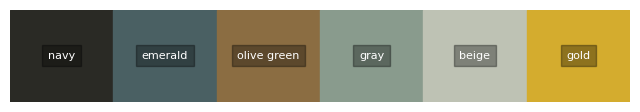

In [7]:
def sintetizar(df, embs, k_paleta=6):
    # paleta global ponderada
    todas = []
    for p in df["paleta_json"]:
        for c in json.loads(p):
            rgb = [int(c["hex"][i:i+2], 16) for i in (1,3,5)]
            todas.append((rgb, c["peso"]))
    X = np.array([t[0] for t in todas]); W = np.array([t[1] for t in todas])
    km = KMeans(n_clusters=k_paleta, n_init=4, random_state=0).fit(X, sample_weight=W)
    peso = np.array([W[km.labels_ == i].sum() for i in range(k_paleta)]); peso /= peso.sum()
    paleta_global = [{"hex": "#%02x%02x%02x" % tuple(km.cluster_centers_[i].astype(int)),
                      "nome": nome_cor(km.cluster_centers_[i]), "peso": float(peso[i])}
                     for i in np.argsort(-peso)]

    estilos_cont = df["estilo_principal"].value_counts().to_dict()
    m = df[["brilho","saturacao","contraste","densidade_bordas","temperatura"]].mean()

    def faixa(v, a, b, tx):  # rótulos em inglês (usados no prompt)
        return tx[0] if v < a else (tx[1] if v < b else tx[2])
    desc = {
        "luz":       faixa(m.brilho, .35, .55, ["dark, moody low-key lighting","balanced lighting","bright luminous lighting"]),
        "contraste": faixa(m.contraste, .15, .25, ["soft low contrast","moderate contrast","strong chiaroscuro contrast"]),
        "cor":       faixa(m.saturacao, .25, .45, ["muted desaturated colors","natural colors","vivid saturated colors"]),
        "traco":     faixa(m.densidade_bordas, .04, .10, ["smooth blended brushwork","visible brushstrokes","highly detailed textured strokes"]),
        "temp":      "warm tones" if m.temperatura > 0.03 else ("cool tones" if m.temperatura < -0.03 else "neutral tones"),
    }
    perfil = {"n_obras": len(df), "estilos": estilos_cont, "medias": m.to_dict(),
              "paleta_global": paleta_global, "descritores": desc}
    with open(os.path.join(PASTA_BANCO, "perfil_estilo.json"), "w") as f:
        json.dump(perfil, f, indent=2, ensure_ascii=False)
    return perfil

PERFIL = sintetizar(df, EMBS)
print(json.dumps({k: PERFIL[k] for k in ("n_obras","estilos","descritores")}, indent=2, ensure_ascii=False))

# visualização da paleta global
fig, ax = plt.subplots(figsize=(8, 1.2))
for i, c in enumerate(PERFIL["paleta_global"]):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=c["hex"])); ax.text(i+.5, .5, c["nome"], ha="center", va="center", fontsize=8, color="white", backgroundcolor="#00000055")
ax.set_xlim(0, len(PERFIL["paleta_global"])); ax.axis("off"); plt.show()

## 8. Carregar o gerador de imagens (Stable Diffusion 1.5 + IP-Adapter) e o tradutor PT→EN

In [8]:
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16, safety_checker=None
).to(DEVICE)
pipe.load_ip_adapter("h94/IP-Adapter", subfolder="models", weight_name="ip-adapter_sd15.bin")

# Tradutor para você poder escrever os pedidos em português
try:
    from transformers import pipeline as hf_pipeline
    _trad = hf_pipeline("translation", model="Helsinki-NLP/opus-mt-ROMANCE-en", device=0)
    def para_ingles(t): return _trad(t, max_length=200)[0]["translation_text"]
except Exception as e:
    print("Tradutor indisponível, escreva os pedidos em inglês.", e)
    def para_ingles(t): return t
print("Pronto para criar.")

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


... (5 outputs left out)

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

Tradutor indisponível, escreva os pedidos em inglês. 'The task translation has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'
Pronto para criar.


## 9. Função principal: `criar_obra(pedido, diretrizes)`

In [9]:
CONECTORES_ESTILO = {"Ukiyo-e Japanese woodblock print": "Ukiyo-e woodblock print"}

def buscar_referencias(pedido_en, estilo=None, k=3):
    e_txt = emb_texto(pedido_en)
    score = EMBS @ e_txt
    if estilo:
        bonus = df["estilo_principal"].str.contains(estilo, case=False).values * 0.05
        score = score + bonus
    idx = np.argsort(-score)[:k]
    return df.iloc[idx], score[idx]

def criar_obra(pedido, diretrizes=None, nome_saida="obra"):
    d = {
        "estilo": None,            # ex.: "Impressionism" (None = usa o do banco)
        "paleta": None,            # ex.: "ochre, teal and deep blue"
        "composicao": None,        # ex.: "centered subject, rule of thirds, wide landscape"
        "extras": None,            # qualquer texto livre (em PT ou EN)
        "evitar": "text, watermark, signature, frame, blurry, low quality, deformed",
        "usar_referencia": True,   # usa a obra mais parecida como referência visual (IP-Adapter)
        "forca_estilo": 0.55,      # 0 = ignora a referência, 1 = copia muito a referência
        "k_referencias": 3, "passos": 30, "guidance": 7.5,
        "largura": 512, "altura": 512, "seed": None,
    }
    d.update(diretrizes or {})

    pedido_en = para_ingles(pedido)
    refs, scores = buscar_referencias(pedido_en, d["estilo"], d["k_referencias"])

    # monta o prompt: pedido + estilo + paleta + traço/luz do perfil
    estilo = d["estilo"] or refs.iloc[0]["estilo_principal"]
    estilo = CONECTORES_ESTILO.get(estilo, estilo)
    if d["paleta"]:
        paleta = para_ingles(d["paleta"])
    else:
        nomes = []
        for _, r in refs.iterrows():
            for c in json.loads(r["paleta_json"])[:3]:
                if c["nome"] not in nomes: nomes.append(c["nome"])
        paleta = ", ".join(nomes[:5])
    pd_ = PERFIL["descritores"]
    partes = [pedido_en, f"in the style of {estilo}", f"palette of {paleta}",
              pd_["luz"], pd_["contraste"], pd_["traco"], pd_["temp"], "masterpiece painting"]
    if d["composicao"]: partes.append(para_ingles(d["composicao"]))
    if d["extras"]:     partes.append(para_ingles(d["extras"]))
    prompt = ", ".join(partes)

    gen = torch.Generator(DEVICE)
    seed = d["seed"] if d["seed"] is not None else int(torch.randint(0, 2**31 - 1, (1,)))
    gen.manual_seed(seed)

    kwargs = dict(prompt=prompt, negative_prompt=d["evitar"], num_inference_steps=d["passos"],
                  guidance_scale=d["guidance"], width=d["largura"], height=d["altura"], generator=gen)
    ref_img = None
    if d["usar_referencia"]:
        ref_img = Image.open(os.path.join(PASTA_OBRAS, refs.iloc[0]["arquivo"])).convert("RGB")
        pipe.set_ip_adapter_scale(d["forca_estilo"])
        kwargs["ip_adapter_image"] = ref_img
    else:
        pipe.set_ip_adapter_scale(0.0)
        kwargs["ip_adapter_image"] = Image.new("RGB", (224, 224), (127, 127, 127))

    img = pipe(**kwargs).images[0]
    caminho = os.path.join(PASTA_SAIDAS, f"{nome_saida}_{seed}.png"); img.save(caminho)

    # mostra referências usadas + resultado
    n = len(refs) + 1
    fig, axs = plt.subplots(1, n, figsize=(4*n, 4))
    for ax, (_, r) in zip(axs, refs.iterrows()):
        ax.imshow(Image.open(os.path.join(PASTA_OBRAS, r["arquivo"]))); ax.set_title("ref: " + r["titulo"][:25], fontsize=9); ax.axis("off")
    axs[-1].imshow(img); axs[-1].set_title("RESULTADO", fontsize=10); axs[-1].axis("off"); plt.show()
    print("Prompt usado:", prompt); print("Seed:", seed, "| Salvo em:", caminho)
    return img

## 10. Peça sua obra!
Edite o **pedido** e as **diretrizes** e rode. Troque a `seed` para variações; use a mesma `seed` para repetir um resultado.

In [17]:
def criar_obra(pedido, diretrizes=None, nome_saida="obra"):
    d = {
        "estilo": None, "paleta": None, "composicao": None, "extras": None,
        "evitar": "text, watermark, signature, frame, blurry, low quality, deformed, extra limbs",
        "usar_referencia": True,
        "forca_estilo": 0.3,         # 0.2-0.4 = obedece mais o texto | 0.6+ = copia a referência
        "usar_perfil": False,        # True = adiciona luz/contraste/traço médios do banco
        "k_referencias": 3, "passos": 30, "guidance": 8.5,
        "largura": 512, "altura": 512, "seed": None,
    }
    d.update(diretrizes or {})

    pedido_en = para_ingles(pedido)
    print("Pedido traduzido:", pedido_en)

    refs, scores = buscar_referencias(pedido_en, d["estilo"], d["k_referencias"])
    estilo = d["estilo"] or refs.iloc[0]["estilo_principal"]
    estilo = CONECTORES_ESTILO.get(estilo, estilo)

    if d["paleta"]:
        paleta = para_ingles(d["paleta"])
    else:
        nomes = []
        for _, r in refs.iterrows():
            for c in json.loads(r["paleta_json"])[:3]:
                if c["nome"] not in nomes: nomes.append(c["nome"])
        paleta = ", ".join(nomes[:4])

    # ordem = prioridade (o que vem primeiro pesa mais)
    partes = [pedido_en]
    if d["composicao"]: partes.append(para_ingles(d["composicao"]))
    partes.append(f"{estilo} painting")
    partes.append(f"{paleta} color palette")
    if d["extras"]: partes.append(para_ingles(d["extras"]))
    if d["usar_perfil"]:
        pd_ = PERFIL["descritores"]
        partes += [pd_["luz"], pd_["contraste"], pd_["traco"]]
    prompt = ", ".join(partes)

    ids = pipe.tokenizer(prompt).input_ids
    if len(ids) > 77:
        print(f"⚠️ Prompt com {len(ids)} tokens; só os primeiros 77 valem. Cortado a partir de:",
              pipe.tokenizer.decode(ids[76:]))

    gen = torch.Generator(DEVICE)
    seed = d["seed"] if d["seed"] is not None else int(torch.randint(0, 2**31 - 1, (1,)))
    gen.manual_seed(seed)

    kwargs = dict(prompt=prompt, negative_prompt=d["evitar"], num_inference_steps=d["passos"],
                  guidance_scale=d["guidance"], width=d["largura"], height=d["altura"], generator=gen)
    if d["usar_referencia"]:
        ref_img = Image.open(os.path.join(PASTA_OBRAS, refs.iloc[0]["arquivo"])).convert("RGB")
        pipe.set_ip_adapter_scale(d["forca_estilo"])
        kwargs["ip_adapter_image"] = ref_img
    else:
        pipe.set_ip_adapter_scale(0.0)
        kwargs["ip_adapter_image"] = Image.new("RGB", (224, 224), (127, 127, 127))

    img = pipe(**kwargs).images[0]
    caminho = os.path.join(PASTA_SAIDAS, f"{nome_saida}_{seed}.png"); img.save(caminho)

    n = len(refs) + 1
    fig, axs = plt.subplots(1, n, figsize=(4*n, 4))
    for ax, (_, r) in zip(axs, refs.iterrows()):
        ax.imshow(Image.open(os.path.join(PASTA_OBRAS, r["arquivo"]))); ax.set_title("ref: " + r["titulo"][:25], fontsize=9); ax.axis("off")
    axs[-1].imshow(img); axs[-1].set_title("RESULTADO", fontsize=10); axs[-1].axis("off"); plt.show()
    print("Prompt:", prompt); print("Seed:", seed, "| Salvo em:", caminho)
    return img

In [21]:
from transformers import Swin2SRForImageSuperResolution, AutoImageProcessor

_sr_proc = AutoImageProcessor.from_pretrained("caidas/swin2SR-classical-sr-x4-64")
_sr = Swin2SRForImageSuperResolution.from_pretrained("caidas/swin2SR-classical-sr-x4-64").to(DEVICE).half().eval()

@torch.no_grad()
def _sr_tile(pil):
    w, h = pil.size
    px = _sr_proc(pil, return_tensors="pt").pixel_values.to(DEVICE).half()
    out = _sr(pixel_values=px).reconstruction.squeeze().float().clamp_(0, 1).cpu().numpy()
    out = (np.moveaxis(out, 0, -1) * 255).round().astype(np.uint8)
    return out[: h * 4, : w * 4]          # remove o padding

def ampliar_x4(img, tile=160, overlap=16):
    # processa em blocos para caber na memória da T4
    w, h = img.size
    out = np.zeros((h * 4, w * 4, 3), np.uint8)
    for y in range(0, h, tile):
        for x in range(0, w, tile):
            x0, y0 = max(x - overlap, 0), max(y - overlap, 0)
            x1, y1 = min(x + tile + overlap, w), min(y + tile + overlap, h)
            up = _sr_tile(img.crop((x0, y0, x1, y1)))
            xe, ye = min(x + tile, w), min(y + tile, h)
            ox, oy = (x - x0) * 4, (y - y0) * 4
            out[y*4:ye*4, x*4:xe*4] = up[oy:oy + (ye - y) * 4, ox:ox + (xe - x) * 4]
    return Image.fromarray(out)

ALVOS_4K = {"16:9": (3840, 2160), "quadrado": (4096, 4096)}

def para_4k(img, formato="16:9"):
    W, H = ALVOS_4K[formato]
    grande = ampliar_x4(img)
    # corta no centro para a proporção exata e ajusta ao tamanho 4K
    r = W / H
    gw, gh = grande.size
    if gw / gh > r:
        nw = int(gh * r); x0 = (gw - nw) // 2; grande = grande.crop((x0, 0, x0 + nw, gh))
    else:
        nh = int(gw / r); y0 = (gh - nh) // 2; grande = grande.crop((0, y0, gw, y0 + nh))
    return grande.resize((W, H), Image.LANCZOS)

def criar_obra_4k(pedido, diretrizes=None, nome_saida="obra", formato="16:9"):
    diretrizes = dict(diretrizes or {})
    # tamanho base de geração (múltiplos de 8), na proporção escolhida
    diretrizes["largura"], diretrizes["altura"] = (768, 432) if formato == "16:9" else (768, 768)
    img = criar_obra(pedido, diretrizes, nome_saida)
    torch.cuda.empty_cache()
    img4k = para_4k(img, formato)
    seed = diretrizes.get("seed", "")
    caminho = os.path.join(PASTA_SAIDAS, f"{nome_saida}_{seed}_4K.png")
    img4k.save(caminho)
    print("4K salvo em:", caminho, "| tamanho:", img4k.size)
    return img4k

preprocessor_config.json:   0%|          | 0.00/152 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.1MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/726 [00:00<?, ?it/s]

Pedido traduzido: um gato pequeno sentado em uma janela, olhando o céu


  0%|          | 0/30 [00:00<?, ?it/s]

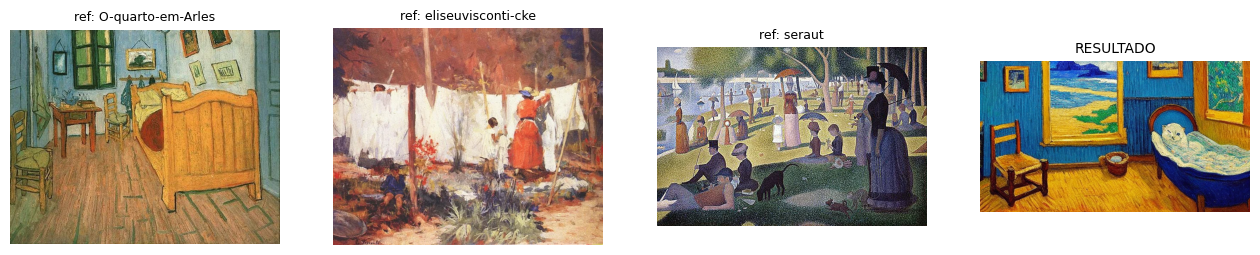

Prompt: um gato pequeno sentado em uma janela, olhando o céu, gato em primeiro plano, céu ocupando metade da tela, Post-Impressionism painting, ocre, azul-petróleo e azul-marinho color palette, pinceladas grossas, atmosfera dramática
Seed: 41 | Salvo em: /content/saidas/gato_41.png
4K salvo em: /content/saidas/gato_41_4K.png | tamanho: (3840, 2160)


In [22]:
img4k = criar_obra_4k(
    pedido="um gato pequeno sentado em uma janela, olhando o céu",
    diretrizes={
        "paleta": "ocre, azul-petróleo e azul-marinho",
        "composicao": "gato em primeiro plano, céu ocupando metade da tela",
        "extras": "pinceladas grossas, atmosfera dramática",
        "forca_estilo": 0.3,
        "seed": 41,
    },
    nome_saida="gato",
    formato="16:9",        # ou "quadrado" para 4096x4096
)